<a href="https://colab.research.google.com/github/Vimachka/211-723Smolskaya/blob/main/SIMILIS_part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# импортируйте библиотеки (pandas, numpy, torch, torchvision, PIL или opencv, matplotlib, sklearn, tqdm);
import sys
import random
import numpy as np
import pandas as pd
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms, datasets, models
from PIL import Image
import matplotlib.pyplot as plt
from sklearn import metrics, model_selection, preprocessing
from tqdm import tqdm
import zipfile
from pathlib import Path

print("PyTorch version:", torch.__version__)
print("TorchVision version:", torchvision.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch version: 2.10.0+cu128
TorchVision version: 0.25.0+cu128
CUDA: True


In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
set_seed(SEED)
print(f"Seed fixed: {SEED}")

Seed fixed: 42


In [5]:
PROJECT_ROOT = Path("/content/archaeo_project")
folders = [
    "data/raw",
    "data/interim",
    "data/processed",
    "splits",
    "artifacts/checkpoints",
    "artifacts/preds",
    "artifacts/reports",
    "artifacts/figures"
]
for f in folders:
    (PROJECT_ROOT / f).mkdir(parents=True, exist_ok=True)
print("Папки созданы:", PROJECT_ROOT)

Папки созданы: /content/archaeo_project


In [6]:
raw_path = PROJECT_ROOT / "data/raw"
for item in raw_path.iterdir():
    print(item.name)

dataset
selected_by_name_iimk_subset_public.csv
.ipynb_checkpoints


In [7]:
!find /content/archaeo_project/data/raw -type f | head -20

/content/archaeo_project/data/raw/dataset/КБ-2014-Р2-0370_orig.jpg
/content/archaeo_project/data/raw/dataset/Нц-46-162_orig.jpg
/content/archaeo_project/data/raw/dataset/КБ-2014-Р5-0102_orig.jpg
/content/archaeo_project/data/raw/dataset/Нейш3А-2018-4942_orig.jpg
/content/archaeo_project/data/raw/dataset/КБ-2014-Р4-368_orig.jpg
/content/archaeo_project/data/raw/dataset/Кроп-2013-285_orig.jpg
/content/archaeo_project/data/raw/dataset/КБ-2014-Р2-0478_orig.jpg
/content/archaeo_project/data/raw/dataset/М102-2012-2-0538_orig.jpg
/content/archaeo_project/data/raw/dataset/БП12-Г02-4270_orig.jpg
/content/archaeo_project/data/raw/dataset/КБ-2014-Р6-202_orig.jpg
/content/archaeo_project/data/raw/dataset/БП12-Г01-4902_orig.jpg
/content/archaeo_project/data/raw/dataset/Нц-52-002_orig.jpg
/content/archaeo_project/data/raw/dataset/КБ-2014-Р2-0701_orig.jpg
/content/archaeo_project/data/raw/dataset/БП11-Р01-Г01-1289_orig.jpg
/content/archaeo_project/data/raw/dataset/БП12-Г01-5772_orig.jpg
/content/arc

In [8]:
import shutil
from pathlib import Path

PROJECT_ROOT = Path("/content/archaeo_project")
RAW = PROJECT_ROOT / "data/raw"

# 1. Удаляем полностью __MACOSX (мусор)
macosx = RAW / "__MACOSX"
if macosx.exists():
    shutil.rmtree(macosx)
    print("Удалена папка __MACOSX")

# 2. Ищем, где лежит настоящая папка с изображениями
# Возможные пути: RAW/cu_data/dataset, RAW/dataset, или где-то ещё
possible_dataset_paths = [
    RAW / "cu_data" / "dataset",
    RAW / "dataset",
    PROJECT_ROOT / "cu_data" / "dataset",
    PROJECT_ROOT / "dataset"
]

dataset_src = None
for p in possible_dataset_paths:
    if p.exists() and p.is_dir():
        # Проверим, есть ли внутри jpg
        jpgs = list(p.glob("*.jpg"))
        if jpgs:
            dataset_src = p
            print(f"Найдена папка dataset: {dataset_src}, файлов .jpg: {len(jpgs)}")
            break

if dataset_src is None:
    # Если не нашли, поищем все jpg в RAW и выше
    all_jpgs = list(RAW.rglob("*.jpg"))
    if all_jpgs:
        print(f"Найдены JPG в разных местах, всего {len(all_jpgs)}. Будем собирать.")
        # Создадим целевую папку dataset
        dataset_dst = RAW / "dataset"
        dataset_dst.mkdir(exist_ok=True)
        for jpg in all_jpgs:
            shutil.move(str(jpg), str(dataset_dst / jpg.name))
        print("Все JPG собраны в data/raw/dataset")
        dataset_src = dataset_dst
    else:
        print("Нет JPG файлов! Проверьте, правильно ли распакован архив.")
else:
    # Перемещаем найденную папку dataset в data/raw (если ещё не там)
    dataset_dst = RAW / "dataset"
    if dataset_src != dataset_dst:
        if dataset_dst.exists():
            shutil.rmtree(dataset_dst)
        shutil.move(str(dataset_src), str(dataset_dst))
        print(f"Папка dataset перемещена в {dataset_dst}")

# 3. Ищем CSV-файл (скорее всего без расширения)
csv_candidates = list(RAW.rglob("selected_by_name_iimk_subset_public*"))
if not csv_candidates:
    csv_candidates = list(RAW.rglob("*.csv")) + list(RAW.rglob("*subset*"))

csv_src = None
for c in csv_candidates:
    if c.is_file():
        csv_src = c
        print(f"Найден CSV: {csv_src}")
        break

if csv_src:
    csv_dst = RAW / "selected_by_name_iimk_subset_public.csv"
    if csv_src != csv_dst:
        shutil.move(str(csv_src), str(csv_dst))
        print(f"CSV перемещён в {csv_dst}")
else:
    print("CSV не найден. Проверьте содержимое data/raw.")

# 4. Удаляем пустую папку cu_data, если осталась
cu_data = RAW / "cu_data"
if cu_data.exists() and cu_data.is_dir():
    try:
        cu_data.rmdir()  # только если пустая
        print("Удалена пустая папка cu_data")
    except OSError:
        print("Папка cu_data не пуста, оставлена.")

# 5. Финальная проверка
print("\n=== Итоговая структура data/raw ===")
for item in RAW.iterdir():
    if item.is_dir():
        num_jpg = len(list(item.glob("*.jpg"))) if item.name == "dataset" else "папка"
        print(f"📁 {item.name}   ({num_jpg} JPG)" if item.name == "dataset" else f"📁 {item.name}")
    else:
        print(f"📄 {item.name}")

Найдена папка dataset: /content/archaeo_project/data/raw/dataset, файлов .jpg: 1388
Найден CSV: /content/archaeo_project/data/raw/selected_by_name_iimk_subset_public.csv

=== Итоговая структура data/raw ===
📁 dataset   (1388 JPG)
📄 selected_by_name_iimk_subset_public.csv
📁 .ipynb_checkpoints


In [9]:
import shutil
from pathlib import Path

RAW = Path("/content/archaeo_project/data/raw")

# 1. Удаляем dataset.zip (уже распакован)
zip_path = RAW / "dataset.zip"
if zip_path.exists():
    zip_path.unlink()
    print("Удалён dataset.zip")

# 2. Удаляем папку cu_data
cu_data = RAW / "cu_data"
if cu_data.exists():
    shutil.rmtree(cu_data)
    print("Удалена папка cu_data")

# 3. Проверяем финальную структуру
print("\n=== Финальная структура data/raw ===")
for item in RAW.iterdir():
    if item.is_dir():
        num_files = len(list(item.glob("*")))
        print(f"📁 {item.name}/  ({num_files} элементов)")
    else:
        print(f"📄 {item.name}")


=== Финальная структура data/raw ===
📁 dataset/  (1388 элементов)
📄 selected_by_name_iimk_subset_public.csv
📁 .ipynb_checkpoints/  (0 элементов)


In [10]:
import unicodedata
import pandas as pd
from pathlib import Path

def nfc(s):
    return unicodedata.normalize('NFC', str(s))

# Пути
dataset_path = Path("/content/archaeo_project/data/raw/dataset")
csv_path = Path("/content/archaeo_project/data/raw/selected_by_name_iimk_subset_public.csv")
interim = Path("/content/archaeo_project/data/interim")

# 1. Удаляем явно мусорный файл
trash = dataset_path / "orig.jpg"
if trash.exists():
    trash.unlink()
    print("Удалён orig.jpg")

# 2. Загружаем файлы и CSV
files = list(dataset_path.glob("*.jpg"))
file_dict = {nfc(f.name.replace('_orig.jpg', '')): f.name for f in files}

df = pd.read_csv(csv_path)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 3. Нормализуем коды CSV
df['code_nfc'] = df['code'].astype(str).apply(nfc)

# 4. Оставляем только существующие
df_matched = df[df['code_nfc'].isin(file_dict.keys())].copy()
df_matched['image_file'] = df_matched['code_nfc'].map(file_dict)
df_matched = df_matched.drop(columns=['code_nfc'])

# 5. Сохраняем
df_matched.to_csv(interim / "annotations_full.csv", index=False)
print(f"Сохранено {len(df_matched)} образцов в '{interim / 'annotations_full.csv'}'")

# 6. Небольшая проверка
print("\nПервые 5 строк:")
print(df_matched.head())

Удалён orig.jpg
Сохранено 1387 образцов в '/content/archaeo_project/data/interim/annotations_full.csv'

Первые 5 строк:
               code     name  \
0  М102-2012-1-0494  Изразец   
1  М102-2012-1-0496  Изразец   
2  М102-2012-1-0529  Изразец   
3  М102-2012-1-0585  Тарелка   
4  М102-2012-1-0603  Изразец   

                                         description  material  \
0  Изразца красноглиняного с белой поливой и коба...  Керамика   
1  Изразца красноглиняного плоского с белой полив...  Керамика   
2  Изразца-перемычки красноглиняного с белой поли...  Керамика   
3  Сосуда (тарелки ?) фаянсового с белой поливой ...     Фаянс   
4  Изразца (перемычки?) красноглиняного с белой п...  Керамика   

                    size     fragm               cultlayer   execorg  \
0    7+ х 3,5+ х 1,1+ см  Фрагмент  Пестрая мешаная супесь  ИИМК РАН   
1  9,9+ х 6,4+ х 1,3+ см  Фрагмент  Пестрая мешаная супесь  ИИМК РАН   
2   4,5+ х 4,3 х 4,2+ см  Фрагмент  Пестрая мешаная супесь  ИИМК РАН   
3 

**ЗАДАНИЕ 2**

In [11]:
from pathlib import Path
import pandas as pd

# Корневая директория проекта (данные уже загружены вручную)
PROJECT_ROOT = Path("/content/archaeo_project")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
IMAGES_DIR = RAW_DIR / "dataset"
CSV_PATH = RAW_DIR / "selected_by_name_iimk_subset_public.csv"

print("Корень raw-данных:", RAW_DIR)
print("Папка с изображениями:", IMAGES_DIR)
print("Файл аннотаций:", CSV_PATH)

Корень raw-данных: /content/archaeo_project/data/raw
Папка с изображениями: /content/archaeo_project/data/raw/dataset
Файл аннотаций: /content/archaeo_project/data/raw/selected_by_name_iimk_subset_public.csv


In [12]:
# Количество изображений
image_files = list(IMAGES_DIR.glob("*.jpg"))
print(f"Количество JPG-файлов в {IMAGES_DIR}: {len(image_files)}")

# Количество строк в CSV
if CSV_PATH.exists():
    df_raw = pd.read_csv(CSV_PATH)
    print(f"Количество строк в CSV (исходное): {len(df_raw)}")
else:
    print("CSV не найден!")

Количество JPG-файлов в /content/archaeo_project/data/raw/dataset: 1387
Количество строк в CSV (исходное): 1389


In [13]:
print("\nПервые 5 строк исходного CSV:")
df_raw.head()


Первые 5 строк исходного CSV:


,Unnamed: 0,code,name,description,material,size,fragm,cultlayer,execorg,survyear
0,40,М102-2012-1-0494,Изразец,Изразца красноглиняного с белой поливой и коба...,Керамика,"7+ х 3,5+ х 1,1+ см",Фрагмент,Пестрая мешаная супесь,ИИМК РАН,2012.0
1,41,М102-2012-1-0496,Изразец,Изразца красноглиняного плоского с белой полив...,Керамика,"9,9+ х 6,4+ х 1,3+ см",Фрагмент,Пестрая мешаная супесь,ИИМК РАН,2012.0
2,49,М102-2012-1-0529,Изразец,Изразца-перемычки красноглиняного с белой поли...,Керамика,"4,5+ х 4,3 х 4,2+ см",Фрагмент,Пестрая мешаная супесь,ИИМК РАН,2012.0
3,59,М102-2012-1-0585,Тарелка,Сосуда (тарелки ?) фаянсового с белой поливой ...,Фаянс,D? см,Фрагмент,Дерн со щепой,ИИМК РАН,2012.0
4,63,М102-2012-1-0603,Изразец,Изразца (перемычки?) красноглиняного с белой п...,Керамика,"3,8+ х 2,8 х 5,1+ см",Фрагмент,Дерн со щепой,ИИМК РАН,2012.0


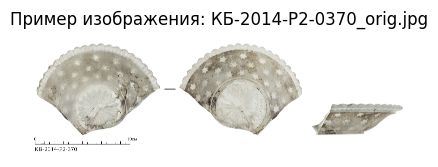

In [14]:
from PIL import Image
import matplotlib.pyplot as plt

# Возьмём первый попавшийся файл
sample_image = image_files[0]
img = Image.open(sample_image)

plt.figure(figsize=(5,5))
plt.imshow(img)
plt.title(f"Пример изображения: {sample_image.name}")
plt.axis('off')
plt.show()

**Задание 3 (3 балла). Проверить структуру датасета и связать изображения с метаданными**

In [15]:
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

RAW_DIR = Path("/content/archaeo_project/data/raw")
IMAGES_DIR = RAW_DIR / "dataset"
CSV_RAW = RAW_DIR / "selected_by_name_iimk_subset_public.csv"

# Загружаем raw CSV
df_raw = pd.read_csv(CSV_RAW)
if 'Unnamed: 0' in df_raw.columns:
    df_raw = df_raw.drop(columns=['Unnamed: 0'])

print("Колонки таблицы:")
print(df_raw.columns.tolist())
print(f"\nВсего строк в raw CSV: {len(df_raw)}")

Колонки таблицы:
['code', 'name', 'description', 'material', 'size', 'fragm', 'cultlayer', 'execorg', 'survyear']

Всего строк в raw CSV: 1389


In [16]:
# Смотрим, какие файлы реально есть в папке dataset
existing_files = {f.name for f in IMAGES_DIR.glob("*.jpg")}

# Для каждой строки CSV формируем ожидаемое имя файла
df_raw['expected_image'] = df_raw['code'].astype(str) + '_orig.jpg'

# Проверяем, существует ли файл
df_raw['image_exists'] = df_raw['expected_image'].isin(existing_files)

valid_count = df_raw['image_exists'].sum()
broken_count = (~df_raw['image_exists']).sum()
duplicate_images = df_raw['expected_image'].duplicated().sum()

print(f"Строк с валидным путём: {valid_count}")
print(f"Битых путей (файл отсутствует): {broken_count}")
print(f"Дублирующихся image_file в CSV: {duplicate_images}")

# Дубликаты по artifact_id (code)
code_duplicates = df_raw['code'].duplicated().sum()
print(f"Повторов artifact_id (code) в CSV: {code_duplicates}")

Строк с валидным путём: 1139
Битых путей (файл отсутствует): 250
Дублирующихся image_file в CSV: 1
Повторов artifact_id (code) в CSV: 1


In [17]:
# Создаём прокси-ключ: первые три части кода (пример: М102-2012-1)
df_raw['group_key'] = df_raw['code'].apply(lambda x: '-'.join(str(x).split('-')[:3]))

# Смотрим, сколько уникальных групп и есть ли повторы среди групп
groups = df_raw['group_key']
print(f"Уникальных групп: {groups.nunique()}")
print("Распределение размера групп (сколько записей в группе):")
print(groups.value_counts().value_counts().sort_index())

Уникальных групп: 837
Распределение размера групп (сколько записей в группе):
count
1      814
2        6
5        2
8        1
16       1
17       1
18       1
20       1
24       1
27       3
32       1
33       1
34       1
41       1
68       1
161      1
Name: count, dtype: int64


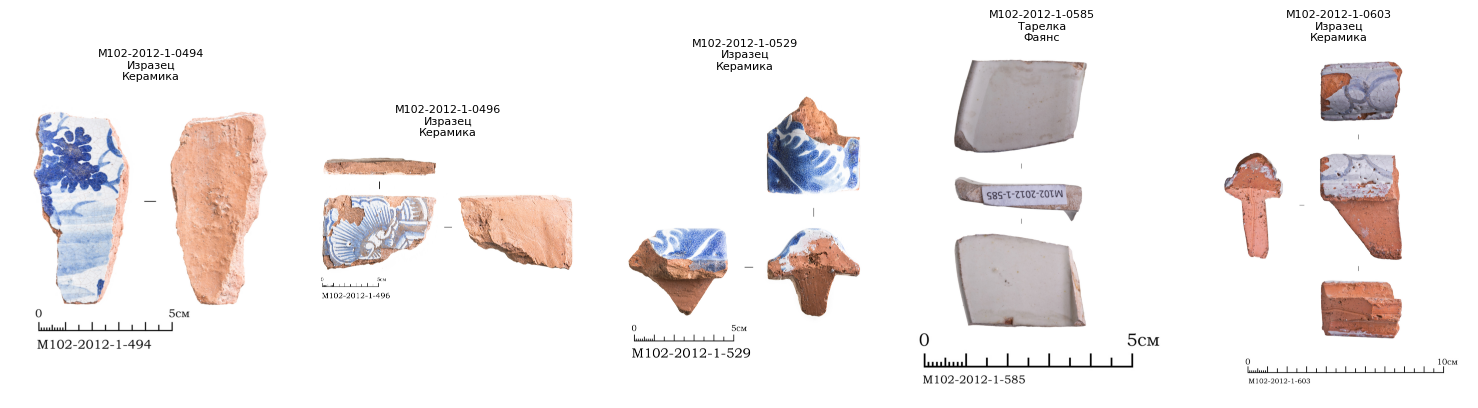

,code,name,material,expected_image
0,М102-2012-1-0494,Изразец,Керамика,М102-2012-1-0494_orig.jpg
1,М102-2012-1-0496,Изразец,Керамика,М102-2012-1-0496_orig.jpg
2,М102-2012-1-0529,Изразец,Керамика,М102-2012-1-0529_orig.jpg
3,М102-2012-1-0585,Тарелка,Фаянс,М102-2012-1-0585_orig.jpg
4,М102-2012-1-0603,Изразец,Керамика,М102-2012-1-0603_orig.jpg


In [18]:
# Берём первые 5 валидных строк
valid_rows = df_raw[df_raw['image_exists']].head(5)

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, (idx, row) in zip(axes, valid_rows.iterrows()):
    img_path = IMAGES_DIR / row['expected_image']
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(f"{row['code']}\n{row['name']}\n{row['material']}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Выведем таблицу с этими строками
valid_rows[['code', 'name', 'material', 'expected_image']]

In [19]:
import pandas as pd
from pathlib import Path

csv_path = Path("/content/archaeo_project/data/raw/selected_by_name_iimk_subset_public.csv")
df = pd.read_csv(csv_path)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Колонки в CSV:", df.columns.tolist())
print(f"Всего записей: {len(df)}")
print("Первые 10 code:")
print(df['code'].head(10))

Колонки в CSV: ['code', 'name', 'description', 'material', 'size', 'fragm', 'cultlayer', 'execorg', 'survyear']
Всего записей: 1389
Первые 10 code:
0    М102-2012-1-0494
1    М102-2012-1-0496
2    М102-2012-1-0529
3    М102-2012-1-0585
4    М102-2012-1-0603
5    М102-2012-1-0611
6    М102-2012-1-0691
7    М102-2012-1-0752
8    М102-2012-1-0827
9    М102-2012-1-0833
Name: code, dtype: object


In [20]:
dataset_path = Path("/content/archaeo_project/data/raw/dataset")
files = list(dataset_path.glob("*.jpg"))
print(f"Всего файлов: {len(files)}")
print("Первые 10 имён файлов:")
for f in files[:10]:
    print(f.name)

Всего файлов: 1387
Первые 10 имён файлов:
КБ-2014-Р2-0370_orig.jpg
Нц-46-162_orig.jpg
КБ-2014-Р5-0102_orig.jpg
Нейш3А-2018-4942_orig.jpg
КБ-2014-Р4-368_orig.jpg
Кроп-2013-285_orig.jpg
КБ-2014-Р2-0478_orig.jpg
М102-2012-2-0538_orig.jpg
БП12-Г02-4270_orig.jpg
КБ-2014-Р6-202_orig.jpg


In [21]:
# Извлекаем code из имени файла (убираем _orig.jpg)
file_codes = [f.name.replace('_orig.jpg', '') for f in files]

# Посмотрим, сколько таких кодов присутствует в колонке 'code' CSV
csv_codes = set(df['code'].astype(str))
matched_codes = [c for c in file_codes if c in csv_codes]
print(f"Из {len(file_codes)} файлов совпадает с CSV: {len(matched_codes)}")
print("Примеры совпавших:", matched_codes[:5])

Из 1387 файлов совпадает с CSV: 1139
Примеры совпавших: ['КБ-2014-Р2-0370', 'Нц-46-162', 'КБ-2014-Р5-0102', 'КБ-2014-Р4-368', 'Кроп-2013-285']


In [22]:
missing_codes = [c for c in file_codes if c not in csv_codes]
print(f"Файлов без соответствия в CSV: {len(missing_codes)}")
print("Первые 20 таких имён (как есть из имени файла):")
for c in missing_codes[:20]:
    print(" ", c)

Файлов без соответствия в CSV: 248
Первые 20 таких имён (как есть из имени файла):
  Нейш3А-2018-4942
  Нейш3А-2018-0108
  Нейш3А-2018-2329
  Нейш3А-2018-1913
  Нейш3А-2018-5221
  Нейш3А-2018-4743
  Нейш3А-2018-7207
  Нейш3А-2018-2581
  Нейш3А-2018-2926
  Нейш3А-2018-0210
  Нейш3А-2018-5863
  Нейш3А-2018-0871
  Нейш3А-2018-2510
  Нейш3А-2018-3039
  Нейш3А-2018-2476
  Нейш3А-2018-3010
  Нейш3А-2018-0868
  Нейш3А-2018-0102
  Нейш3А-2018-5912
  Нейш3А-2018-0821


In [23]:
# Поиск в CSV всех кодов, начинающихся на 'Нейш3А-2018'
matches = [c for c in csv_codes if 'Нейш3А-2018-4942' in c]
print("Найдено в CSV записей с 'Нейш3А-2018':", len(matches))
print(matches[:10])

Найдено в CSV записей с 'Нейш3А-2018': 1
['Нейш3А-2018-4942']


In [24]:
import unicodedata
from pathlib import Path

def nfc(s):
    return unicodedata.normalize('NFC', s)

dataset_path = Path("/content/archaeo_project/data/raw/dataset")
files = list(dataset_path.glob("*.jpg"))
file_codes_nfc = [nfc(f.name.replace('_orig.jpg', '')) for f in files]

csv_path = Path("/content/archaeo_project/data/raw/selected_by_name_iimk_subset_public.csv")
df = pd.read_csv(csv_path)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])
csv_codes_nfc = set(nfc(c) for c in df['code'].astype(str))

# Теперь смотрим совпадения
matched_codes = [c for c in file_codes_nfc if c in csv_codes_nfc]
print(f"После NFC: совпадает {len(matched_codes)} из {len(files)}")

После NFC: совпадает 1387 из 1387


In [25]:
# Выявим несовпавший код
file_codes_nfc_set = set(file_codes_nfc)
csv_codes_nfc_set = set(csv_codes_nfc)
only_in_files = file_codes_nfc_set - csv_codes_nfc_set
only_in_csv = csv_codes_nfc_set - file_codes_nfc_set
print("Только в файлах (не в CSV):", only_in_files)
print("Только в CSV (не в файлах):", only_in_csv)

Только в файлах (не в CSV): set()
Только в CSV (не в файлах): {'46858'}


In [26]:
file_map = {nfc(f.name.replace('_orig.jpg', '')): f.name for f in files}
df['code_nfc'] = df['code'].astype(str).apply(nfc)
df_matched = df[df['code_nfc'].isin(file_map.keys())].copy()
df_matched['image_file'] = df_matched['code_nfc'].map(file_map)
df_matched = df_matched.drop(columns=['code_nfc'])
df_matched.to_csv("/content/archaeo_project/data/interim/annotations_full.csv", index=False)
print(f"Сохранено {len(df_matched)} записей, все с валидными изображениями.")

Сохранено 1387 записей, все с валидными изображениями.


Задание 4 (4 балла). Провести визуальный и табличный EDA корпуса

Проверка наличия данных...
✅ Загружено 1387 образцов
Колонки: ['code', 'name', 'description', 'material', 'size', 'fragm', 'cultlayer', 'execorg', 'survyear', 'image_file', 'image_path']



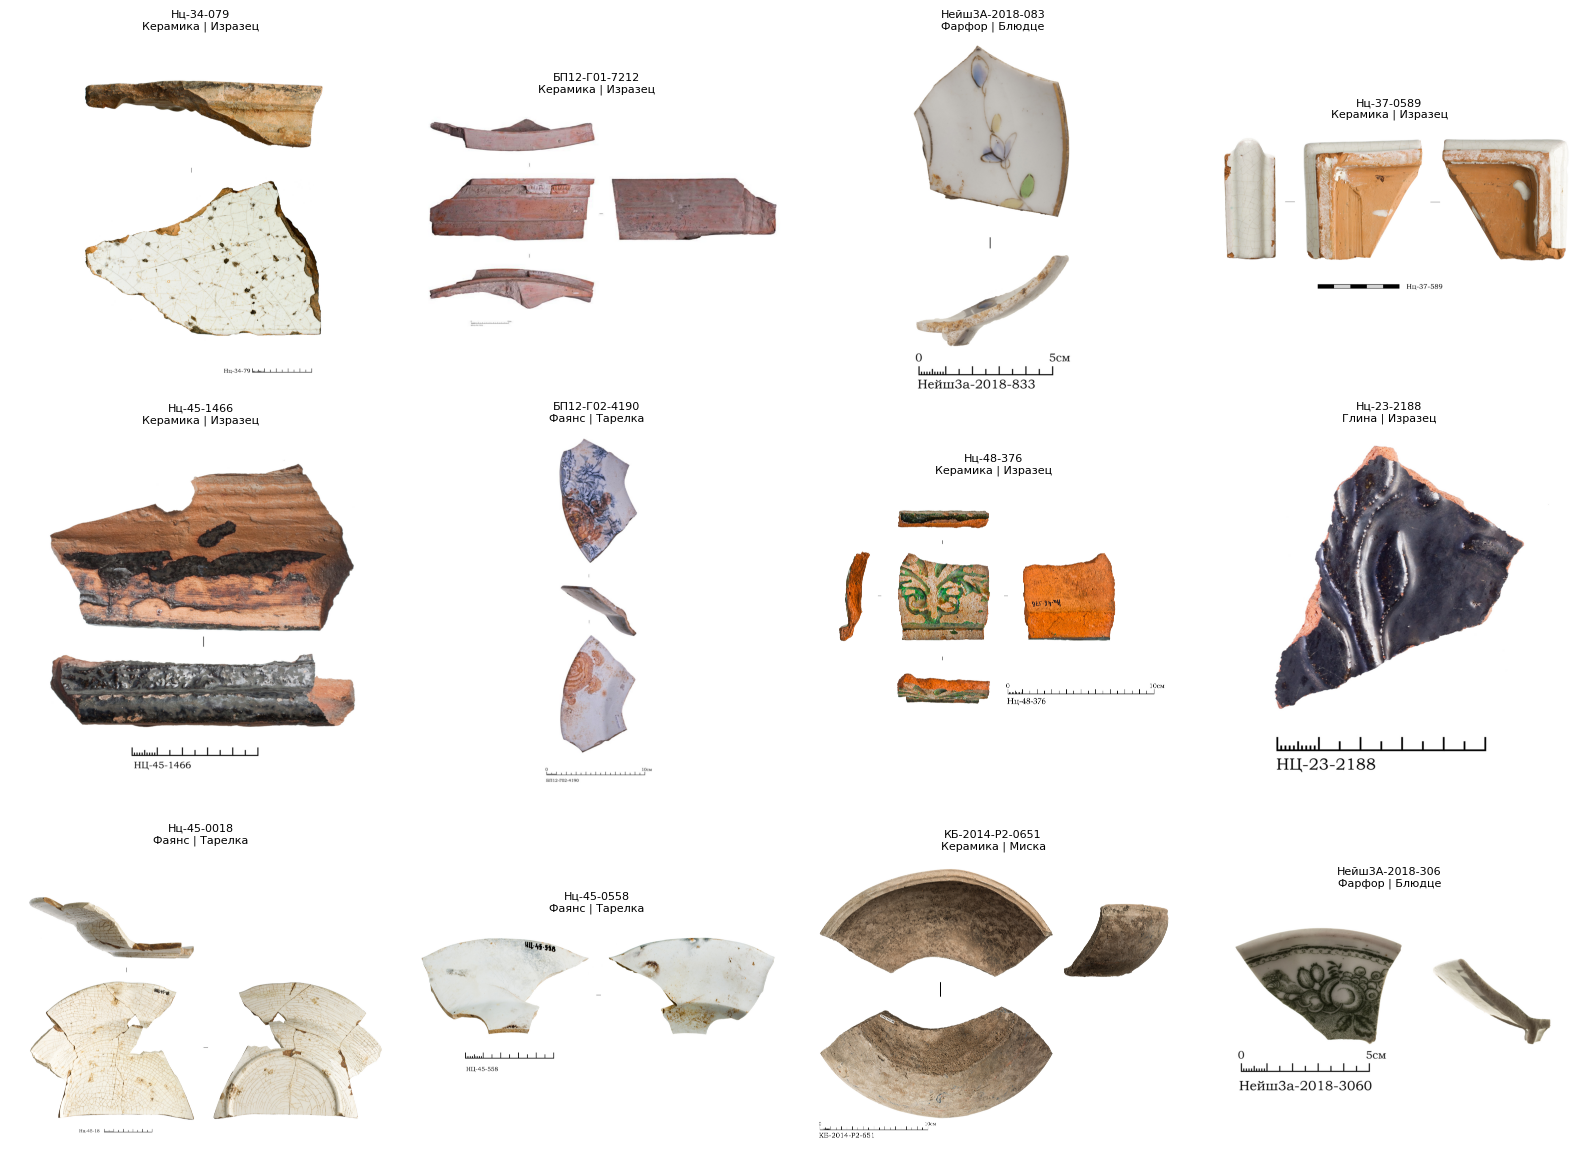

Измеряем размеры: 100%|██████████| 1387/1387 [00:00<00:00, 10349.01it/s]


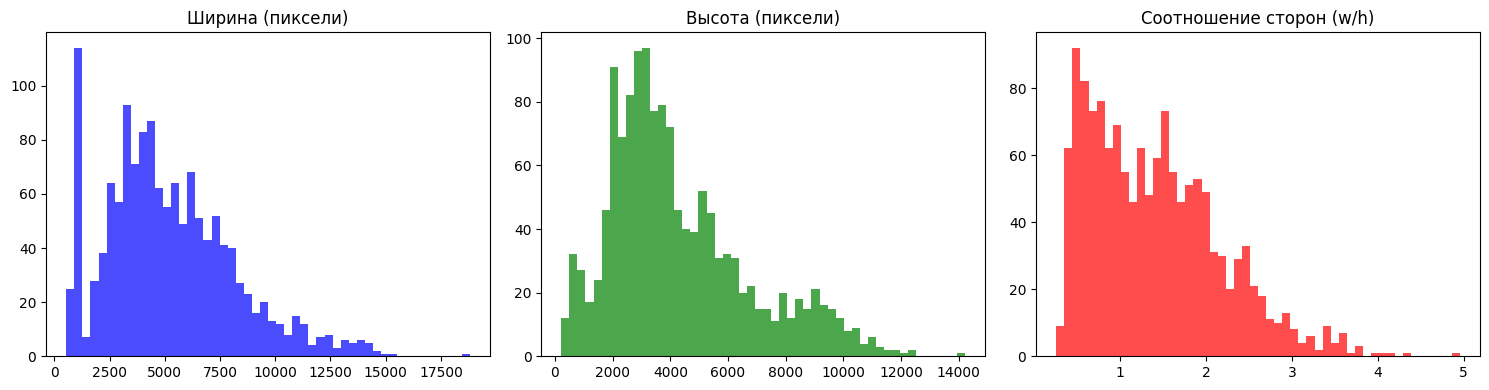

Диапазон ширины: 543–18808 пикс
Диапазон высоты: 218–14212 пикс
Среднее соотношение сторон: 1.41



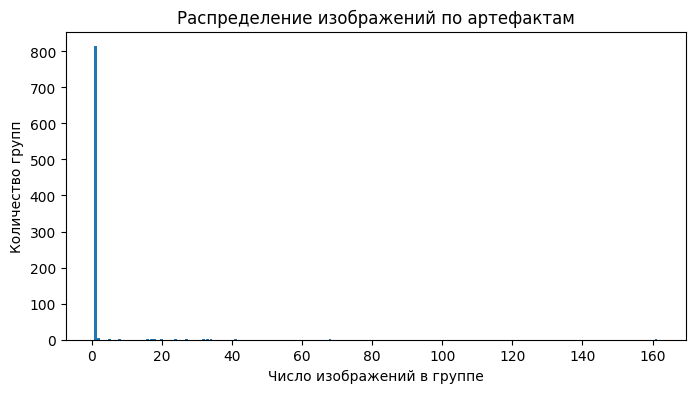

Всего групп: 836
Групп с 1 изображением: 814
Групп с 2–3 изображениями: 5



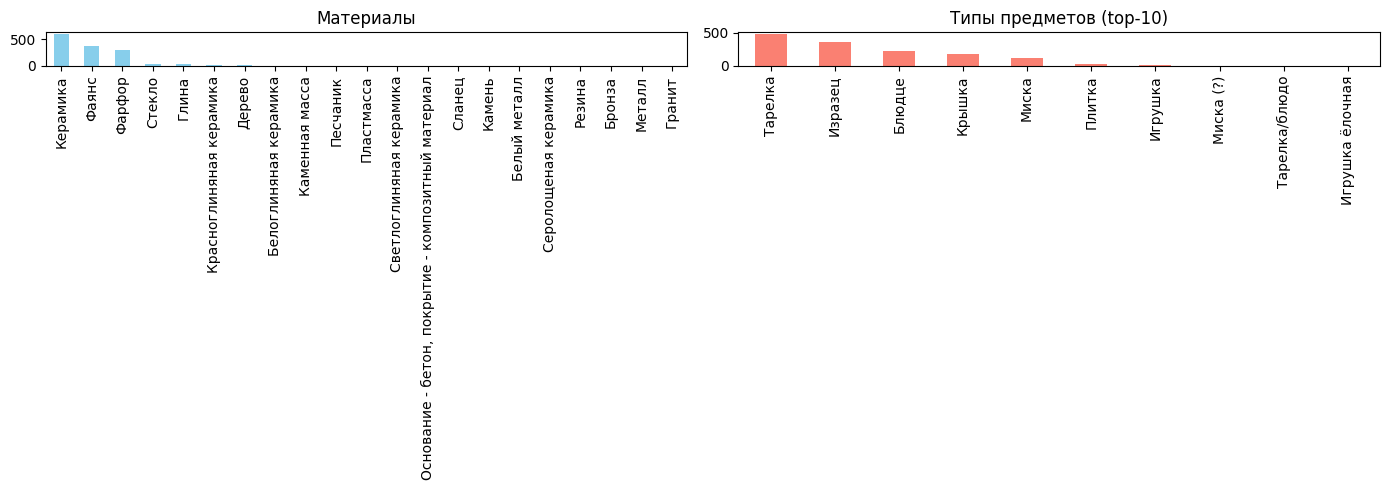

Анализ качества: 100%|██████████| 200/200 [02:16<00:00,  1.46it/s]


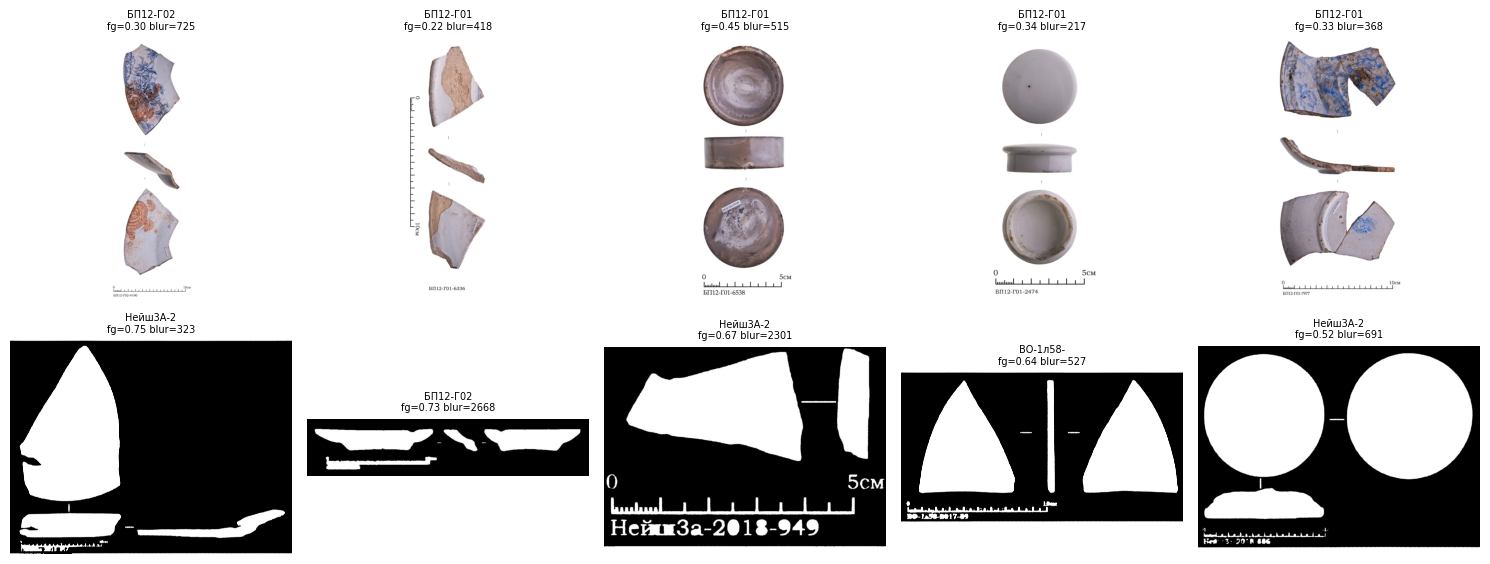


Распределение визуальных режимов на подвыборке (200 изображений):
mode
фрагмент      122
multi-view     70
close-up        8
Name: count, dtype: int64


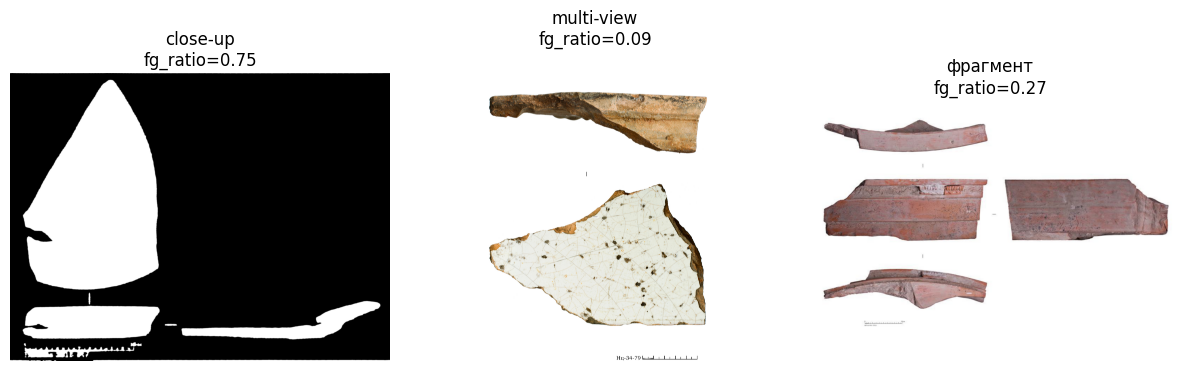

Анализ фона и линеек: 100%|██████████| 200/200 [03:29<00:00,  1.05s/it]


Типы фона на подвыборке:
bg_type
white    198
other      2
Name: count, dtype: int64

Наличие масштабной линейки:
has_scale_bar
True     198
False      2
Name: count, dtype: int64


In [29]:
# анализ наших данных
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL.Image import DecompressionBombError
import cv2
from tqdm import tqdm
import random
import warnings
warnings.filterwarnings('ignore')


PROJECT_ROOT = Path("/content/archaeo_project")
DATASET_DIR = PROJECT_ROOT / "data/raw/dataset"
CSV_PATH = PROJECT_ROOT / "data/interim/annotations_full.csv"
FIGURES_DIR = PROJECT_ROOT / "artifacts/figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Проверка наличия данных...")
if not CSV_PATH.exists():
    raise FileNotFoundError(f"CSV не найден: {CSV_PATH}")
if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Папка с изображениями не найдена: {DATASET_DIR}")

df = pd.read_csv(CSV_PATH)
df['image_path'] = df['image_file'].apply(lambda x: str(DATASET_DIR / x))
print(f"Загружено {len(df)} образцов")
print(f"Колонки: {df.columns.tolist()}\n")

# Увеличиваем лимит для PIL, чтобы не было DecompressionBombError
Image.MAX_IMAGE_PIXELS = None

# СЕТКА ИЗ 12 ИЗОБРАЖЕНИЙ ----------
random.seed(42)
sample = df.sample(12, random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    try:
        img = Image.open(row['image_path'])
        ax.imshow(img)
        ax.set_title(f"{row['code'][:15]}\n{row['material']} | {row['name']}", fontsize=8)
    except Exception as e:
        ax.set_title(f"Ошибка: {row['code']}", fontsize=8)
        ax.imshow(np.zeros((100,100,3), dtype=np.uint8))
    ax.axis('off')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "grid_12_images.png", dpi=150)
plt.show()

# РАСПРЕДЕЛЕНИЯ РАЗМЕРОВ И АСПЕКТОВ
widths, heights = [], []
for p in tqdm(df['image_path'], desc="Измеряем размеры"):
    try:
        with Image.open(p) as img:
            w, h = img.size
            widths.append(w); heights.append(h)
    except Exception:
        continue

df_valid = df.iloc[:len(widths)].copy()
df_valid['width'] = widths
df_valid['height'] = heights
df_valid['aspect'] = df_valid['width'] / df_valid['height']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(widths, bins=50, alpha=0.7, color='blue')
axes[0].set_title('Ширина (пиксели)')
axes[1].hist(heights, bins=50, alpha=0.7, color='green')
axes[1].set_title('Высота (пиксели)')
axes[2].hist(df_valid['aspect'], bins=50, alpha=0.7, color='red')
axes[2].set_title('Соотношение сторон (w/h)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "size_distributions.png", dpi=150)
plt.show()

print(f"Диапазон ширины: {min(widths)}–{max(widths)} пикс")
print(f"Диапазон высоты: {min(heights)}–{max(heights)} пикс")
print(f"Среднее соотношение сторон: {np.mean(df_valid['aspect']):.2f}\n")

# ЧИСЛО ИЗОБРАЖЕНИЙ НА АРТЕФАКТ (ГРУППА)
df['group_key'] = df['code'].apply(lambda x: '-'.join(str(x).split('-')[:3]))
group_counts = df['group_key'].value_counts()
plt.figure(figsize=(8,4))
plt.hist(group_counts, bins=range(1, group_counts.max()+2), align='left', rwidth=0.8)
plt.xlabel('Число изображений в группе')
plt.ylabel('Количество групп')
plt.title('Распределение изображений по артефактам')
plt.savefig(FIGURES_DIR / "group_distribution.png", dpi=150)
plt.show()
print(f"Всего групп: {len(group_counts)}")
print(f"Групп с 1 изображением: {(group_counts == 1).sum()}")
print(f"Групп с 2–3 изображениями: {((group_counts >= 2) & (group_counts <= 3)).sum()}\n")

# БАЗОВЫЕ ПОЛЯ (МАТЕРИАЛЫ, ТИПЫ)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df['material'].value_counts().plot(kind='bar', ax=axes[0], color='skyblue')
axes[0].set_title('Материалы')
axes[0].set_xlabel('')
df['name'].value_counts().head(10).plot(kind='bar', ax=axes[1], color='salmon')
axes[1].set_title('Типы предметов (top-10)')
axes[1].set_xlabel('')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "categorical_distributions.png", dpi=150)
plt.show()

#ПРОБЛЕМНЫЕ ИЗОБРАЖЕНИЯ
def get_brightness(img):
    return cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY).mean()

def get_blurriness(img):
    gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()

def get_fg_ratio(img):
    gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return np.count_nonzero(thresh) / thresh.size

# Берём подвыборку (200) для скорости
sample_problems = df.sample(200, random_state=42).copy()
brightness_vals, blur_vals, fg_vals = [], [], []
for p in tqdm(sample_problems['image_path'], desc="Анализ качества"):
    try:
        img = Image.open(p).convert('RGB')
        brightness_vals.append(get_brightness(img))
        blur_vals.append(get_blurriness(img))
        fg_vals.append(get_fg_ratio(img))
    except Exception:
        brightness_vals.append(0); blur_vals.append(0); fg_vals.append(0)

sample_problems['brightness'] = brightness_vals
sample_problems['blur'] = blur_vals
sample_problems['fg_ratio'] = fg_vals
sample_problems['width'] = sample_problems['image_path'].apply(lambda p: Image.open(p).size[0] if Path(p).exists() else 0)

# Выбираем худшие по каждому критерию
dark = sample_problems.nsmallest(5, 'brightness')
blurry = sample_problems.nsmallest(5, 'blur')
small_obj = sample_problems.nsmallest(5, 'fg_ratio')
crop = sample_problems.nsmallest(5, 'width')
problematic = pd.concat([crop, dark, blurry, small_obj]).drop_duplicates().head(10)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, (_, row) in zip(axes.flat, problematic.iterrows()):
    try:
        img = Image.open(row['image_path'])
        ax.imshow(img)
        ax.set_title(f"{row['code'][:8]}\nfg={row['fg_ratio']:.2f} blur={row['blur']:.0f}", fontsize=7)
    except:
        ax.set_title("Ошибка")
    ax.axis('off')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "problematic_images.png", dpi=150)
plt.show()

# ВИЗУАЛЬНЫЕ РЕЖИМЫ
sample_problems['mode'] = 'фрагмент'
sample_problems.loc[sample_problems['fg_ratio'] > 0.5, 'mode'] = 'close-up'
sample_problems.loc[(sample_problems['fg_ratio'] < 0.2) & (sample_problems['width'] > 1500), 'mode'] = 'multi-view'
print("\nРаспределение визуальных режимов на подвыборке (200 изображений):")
print(sample_problems['mode'].value_counts())

# по одному примеру каждого режима
modes = ['close-up', 'multi-view', 'фрагмент']
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, mode in zip(axes, modes):
    ex = sample_problems[sample_problems['mode'] == mode].iloc[0]
    try:
        img = Image.open(ex['image_path'])
        ax.imshow(img)
        ax.set_title(f"{mode}\nfg_ratio={ex['fg_ratio']:.2f}")
    except:
        ax.set_title(mode)
    ax.axis('off')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "visual_modes.png", dpi=150)
plt.show()

# ОЦЕНКА ФОНА И НАЛИЧИЯ ЛИНЕЙКИ
def bg_type(img):
    # Оцениваем цвет фона: берём угловые пиксели (10x10)
    img_np = np.array(img)
    h, w = img_np.shape[:2]
    corners = [
        img_np[0:10, 0:10].mean(axis=(0,1)),
        img_np[0:10, w-10:w].mean(axis=(0,1)),
        img_np[h-10:h, 0:10].mean(axis=(0,1)),
        img_np[h-10:h, w-10:w].mean(axis=(0,1))
    ]
    avg = np.mean(corners, axis=0)
    if avg.mean() > 200:
        return "white"
    elif avg.mean() > 150:
        return "light-gray"
    else:
        return "other"

def has_scale_bar(img):
    # Простейшая эвристика: ищем длинные горизонтальные линии (линейка)
    gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=100, minLineLength=200, maxLineGap=10)
    if lines is not None:
        for line in lines:
            x1,y1,x2,y2 = line[0]
            if abs(y2-y1) < 5 and (x2-x1) > 150:  # горизонтальная линия
                return True
    return False

# Применяем к тем же 200 изображениям
bg_types = []
has_ruler = []
for p in tqdm(sample_problems['image_path'], desc="Анализ фона и линеек"):
    try:
        img = Image.open(p)
        bg_types.append(bg_type(img))
        has_ruler.append(has_scale_bar(img))
    except:
        bg_types.append("unknown")
        has_ruler.append(False)

sample_problems['bg_type'] = bg_types
sample_problems['has_scale_bar'] = has_ruler

print("\nТипы фона на подвыборке:")
print(sample_problems['bg_type'].value_counts())
print("\nНаличие масштабной линейки:")
print(sample_problems['has_scale_bar'].value_counts())



**Задание 5 (4 балла). Исследовать структуру описаний и выбрать поля для baseline**

In [31]:
import pandas as pd
import numpy as np
from pathlib import Path
import unicodedata


PROJECT_ROOT = Path("/content/archaeo_project")
interim_csv = PROJECT_ROOT / "data/interim/annotations_full.csv"
raw_csv = PROJECT_ROOT / "data/raw/selected_by_name_iimk_subset_public.csv"

if interim_csv.exists():
  df = pd.read_csv(interim_csv)
  print(f"Загружен очищенный файл: {interim_csv}, строк: {len(df)}")
else:
  print('плохо, Вика')

# Создаём вспомогательный признак "наличие росписи/клейма" из description
def has_inscription(desc):
    if pd.isna(desc):
        return 0
    keywords = ['роспис', 'клейм', 'надпис', 'полив', 'орнамент', 'рисунк', 'герб']
    return 1 if any(kw in str(desc).lower() for kw in keywords) else 0

df['has_inscription'] = df['description'].apply(has_inscription)

# 20 реальных описаниый
print("\n=== 20 реальных описаний артефактов ===\n")
for i, row in df.head(20).iterrows():
    print(f"Код: {row['code']}")
    print(f"Название: {row['name']}")
    print(f"Материал: {row['material']}")
    print(f"Описание: {row['description'][:150]}...")
    print("---")

# анализ данных
print("Анализ колонок таблицы")
print("Все колонки:", df.columns.tolist())

# Оцениваем каждую колонку
field_analysis = []

# Список колонок, которые есть в CSV
candidate_fields = ['material', 'name', 'fragm', 'size', 'survyear', 'execorg', 'cultlayer', 'description', 'code']

for field in candidate_fields:
    if field not in df.columns:
        continue
    unique_vals = df[field].nunique()
    missing = df[field].isna().sum()
    missing_pct = missing / len(df) * 100
    # Тип поля (категориальный, текстовый, числовой)
    if field in ['material', 'name', 'fragm']:
        field_type = "категориальный (single-label)"
    elif field == 'size':
        field_type = "текстовый/сложный"
    elif field in ['survyear']:
        field_type = "числовой"
    else:
        field_type = "свободный текст" if field == 'description' else "категориальный"

    # Визуальная наблюдаемость (эвристика)
    if field == 'material':
        visible = "Да – материал (керамика, фаянс, стекло и т.д.) часто различим по цвету, фактуре, блеску."
    elif field == 'name':
        visible = "Да – форма предмета (тарелка, миска, изразец, блюдце) хорошо видна на фото."
    elif field == 'fragm':
        visible = "Да – фрагмент/целый можно оценить по полноте формы."
    elif field == 'has_inscription':
        visible = "Да – наличие росписи, клейма или надписи видно (бинарный признак)."
    elif field == 'size':
        visible = "Нет – размер зависит от масштаба съёмки; без эталона не определить."
    elif field == 'survyear':
        visible = "Нет – год находки не связан с внешним видом."
    elif field == 'execorg':
        visible = "Нет – организация-исполнитель не визуальна."
    elif field == 'cultlayer':
        visible = "Нет – культурный слой – археологический контекст, не виден на фото."
    elif field == 'description':
        visible = "Сложно – генерация текста требует отдельной модели (не baseline)."
    elif field == 'code':
        visible = "Нет – уникальный идентификатор."
    else:
        visible = "Неизвестно"

    risk = "Низкий" if visible.startswith("Да") else "Высокий" if visible.startswith("Нет") else "Средний"
    take_for_baseline = "Да" if visible.startswith("Да") else "Нет"

    field_analysis.append({
        "field_name": field,
        "визуально видно": visible[:60] + "..." if len(visible) > 60 else visible,
        "тип цели": field_type,
        "число классов": unique_vals if field_type.startswith("категориальный") else "-",
        "доля пропусков": f"{missing_pct:.1f}%",
        "риск неоднозначности": risk,
        "брать в baseline": take_for_baseline
    })


df_fields = pd.DataFrame(field_analysis)
print("Оценка всех полей")
print(df_fields.to_string(index=False))

# Выбор 2–4 полей для baseline
baseline_fields = df_fields[df_fields["брать в baseline"] == "Да"]["field_name"].tolist()

if 'has_inscription' not in baseline_fields:
    baseline_fields.append('has_inscription')

# Ограничимся максимум 4 полями (если больше, возьмём первые 4)
baseline_fields = baseline_fields[:4]

print("\n=== ПОЛЯ, ВЫБРАННЫЕ ДЛЯ BASELINE ===")
for f in baseline_fields:
    print(f" - {f}")

# Поля, которые сознательно исключены
excluded_fields = df_fields[df_fields["брать в baseline"] == "Нет"]["field_name"].tolist()
print("\n=== ПОЛЯ, ИСКЛЮЧЁННЫЕ ИЗ BASELINE ===")
for f in excluded_fields:
    reason = df_fields[df_fields["field_name"] == f]["визуально видно"].values[0]
    print(f" - {f}: {reason}")

print("РАСПРЕДЕЛЕНИЯ ЦЕЛЕВЫХ ПОЛЕЙ")
for f in baseline_fields:
    if f in df.columns:
        print(f"\n{f}:")
        print(df[f].value_counts().head(10))
    elif f == 'has_inscription':
        print("\nhas_inscription (наличие росписи/клейма):")
        print(df['has_inscription'].value_counts())


Загружен очищенный файл: /content/archaeo_project/data/interim/annotations_full.csv, строк: 1387

=== 20 реальных описаний артефактов ===

Код: М102-2012-1-0494
Название: Изразец
Материал: Керамика
Описание: Изразца красноглиняного с белой поливой и кобальтовой (растительной либо сюжетной ?) росписью фр-т...
---
Код: М102-2012-1-0496
Название: Изразец
Материал: Керамика
Описание: Изразца красноглиняного плоского с белой поливой и голубой росписью фр-т...
---
Код: М102-2012-1-0529
Название: Изразец
Материал: Керамика
Описание: Изразца-перемычки красноглиняного с белой поливой и кобальтовой растительной росписью фр-т...
---
Код: М102-2012-1-0585
Название: Тарелка
Материал: Фаянс
Описание: Сосуда (тарелки ?) фаянсового с белой поливой внутри и снаружи края фр-т...
---
Код: М102-2012-1-0603
Название: Изразец
Материал: Керамика
Описание: Изразца (перемычки?) красноглиняного с белой поливой и голубой росписью фр-т...
---
Код: М102-2012-1-0611
Название: Изразец
Материал: Керамика
Описание: Из

**material, name, fragm, has_inscription**

**Задание 6 (3 балла). Нормализовать словари и собрать целевые колонки**

In [32]:
import pandas as pd
import numpy as np
from collections import Counter


# нормализация поля 'material'
print("=== 1. Нормализация material ===\n")
print("Исходные уникальные значения material:")
print(sorted(df['material'].unique()))

# Определим словарь нормализации
material_mapping = {
    'Керамика': 'Керамика',
    'Красноглиняная керамика': 'Керамика',
    'Белоглиняная керамика': 'Керамика',
    'Светлоглиняная керамика': 'Керамика',
    'Глина': 'Керамика',                     # Глина тоже керамика ?
    'Каменная масса': 'Каменная масса',
    'Камень': 'Камень',
    'Песчаник': 'Камень',
    'Сланец': 'Камень',
    'Фаянс': 'Фаянс',
    'Фарфор': 'Фарфор',
    'Стекло': 'Стекло',
    'Дерево': 'Дерево',
    'Пластмасса': 'Пластмасса',
    'Металл': 'Металл',
    'Бронза': 'Металл',
    'Белый металл': 'Металл',
    'Резина': 'Резина',
    'Гранит': 'Камень',
    'Бетон, покрытие - композитный материал': 'Композит',
    'Керамика (красноглиняная)': 'Керамика', # доп варианты
    'Серолощеная керамика': 'Керамика',
}

# Нормализуем
df['norm_material'] = df['material'].map(material_mapping).fillna('Другое')
df['material_is_missing'] = df['material'].isna()
df['material_is_uncertain'] = False  # нет явных '?' в material

# Проверим, остались ли ненормализованные значения
unknown_materials = set(df[df['norm_material'] == 'Другое']['material'].unique())
print(f"\nНормализованные значения: {sorted(df['norm_material'].unique())}")
print(f"Не распознанные исходные материалы (попадут в 'Другое'): {unknown_materials}")
print("Распределение после нормализации:")
print(df['norm_material'].value_counts())

# 2. Нормализация поля 'name'
print("Исходные уникальные значения name (первые 20):")
print(sorted(df['name'].unique())[:20])

# Словарь нормализации названий
# Объединяем синонимы, убираем знаки вопроса, группируем редкие
name_mapping = {
    'Тарелка': 'Тарелка',
    'Изразец': 'Изразец',
    'Блюдце': 'Блюдце',
    'Крышка': 'Крышка',
    'Миска': 'Миска',
    'Плитка': 'Плитка',
    'Игрушка': 'Игрушка',
    'Миска (?)': 'Миска',
    'Тарелка/блюдо': 'Тарелка',    # основное блюдо/тарелка
    'Игрушка ёлочная': 'Игрушка',
    'Тарелка/блюдо (?)': 'Тарелка',
    'Миска (?) (?)': 'Миска',
    'Крышка (?)': 'Крышка',
}

# Добавим все уникальные значения, которые не вошли в маппинг, в 'Другое'
unique_names = set(df['name'].unique())
for name in unique_names:
    if name not in name_mapping:
        # Если встречается редко, можно отнести в 'Другое'
        cnt = (df['name'] == name).sum()
        if cnt < 10:
            name_mapping[name] = 'Другое'
        else:
            # Например, 'Плитка' уже есть, а 'Плитка (другое)' может быть, но в наших данных нет
            # Для безопасности оставим как есть с добавлением префикса
            name_mapping[name] = name  # если не редкое, оставляем как есть

# Но лучше вручную просмотреть редкие:
rare_names = [n for n in unique_names if (df['name'] == n).sum() < 10]
print(f"\nРедкие названия (менее 10 встреч): {rare_names}")
for n in rare_names:
    name_mapping[n] = 'Другое'


=== 1. Нормализация material ===

Исходные уникальные значения material:
['Белоглиняная керамика', 'Белый металл', 'Бронза', 'Глина', 'Гранит', 'Дерево', 'Каменная масса', 'Камень', 'Керамика', 'Красноглиняная керамика', 'Металл', 'Основание - бетон, покрытие - композитный материал', 'Песчаник', 'Пластмасса', 'Резина', 'Светлоглиняная керамика', 'Серолощеная керамика', 'Сланец', 'Стекло', 'Фарфор', 'Фаянс']

Нормализованные значения: ['Дерево', 'Другое', 'Каменная масса', 'Камень', 'Керамика', 'Металл', 'Пластмасса', 'Резина', 'Стекло', 'Фарфор', 'Фаянс']
Не распознанные исходные материалы (попадут в 'Другое'): {'Основание - бетон, покрытие - композитный материал'}
Распределение после нормализации:
norm_material
Керамика          656
Фаянс             368
Фарфор            307
Стекло             28
Дерево              9
Камень              8
Каменная масса      3
Металл              3
Другое              2
Пластмасса          2
Резина              1
Name: count, dtype: int64
Исходные у

In [35]:
#  Применяем маппинг
df['norm_name'] = df['name'].map(name_mapping).fillna('Другое')
df['name_is_missing'] = df['name'].isna()
df['name_is_uncertain'] = df['name'].str.contains(r'\?', na=False)

print("\nНормализованные значения name:")
print(sorted(df['norm_name'].unique()))
print("\nРаспределение после нормализации (топ-10):")
print(df['norm_name'].value_counts().head(10))

# 3. Поле 'fragm'
print("Исходные значения:", df['fragm'].unique())
df['norm_fragm'] = df['fragm'].map({'Фрагмент': 0, 'Целый': 1}).fillna(-1)
df['fragm_is_missing'] = df['fragm'].isna()
df['fragm_is_uncertain'] = False
print("Нормализовано: 0 = Фрагмент, 1 = Целый")
print("Распределение:\n", df['norm_fragm'].value_counts())

# 4. Поле 'has_inscription'
df['norm_inscription'] = df['has_inscription'].astype(int)
df['inscription_is_missing'] = df['has_inscription'].isna()
df['inscription_is_uncertain'] = False   # мы создавали его автоматически, без неопределённости
print("Распределение после нормализации:")
print(df['norm_inscription'].value_counts())

# 5. Сводная информация по нормализации
print("\n ИТОГОВАЯ СТАТИСТИКА ПО НОРМАЛИЗАЦИИ\n")
for field in ['material', 'name', 'fragm', 'inscription']:
    col = f'norm_{field}'
    if col in df.columns:
        n_classes = df[col].nunique()
        print(f"{field}: число классов после нормализации = {n_classes}")
        print(f"  Пропуски: {df[f'{field}_is_missing'].sum()}")
        print(f"  Неоднозначные: {df[f'{field}_is_uncertain'].sum()}")

print("\nПРИМЕРЫ НОРМАЛИЗАЦИИ (словари) \n")
print("material (сырое => нормализованное):")
for raw, norm in list(material_mapping.items())[:10]:
    print(f"  {raw} => {norm}")

print("\nname (редкие => 'Другое'):")
for n in rare_names[:10]:
    print(f"  {n} => Другое")
print("  ...")
print("  'Тарелка/блюдо' => Тарелка")
print("  'Миска (?)' => Миска")


Нормализованные значения name:
['Блюдце', 'Другое', 'Изразец', 'Крышка', 'Миска', 'Плитка', 'Тарелка']

Распределение после нормализации (топ-10):
norm_name
Тарелка    480
Изразец    361
Блюдце     216
Крышка     177
Миска      113
Плитка      26
Другое      14
Name: count, dtype: int64
Исходные значения: ['Фрагмент' 'Целый']
Нормализовано: 0 = Фрагмент, 1 = Целый
Распределение:
 norm_fragm
0    1258
1     129
Name: count, dtype: int64
Распределение после нормализации:
norm_inscription
1    1150
0     237
Name: count, dtype: int64

 ИТОГОВАЯ СТАТИСТИКА ПО НОРМАЛИЗАЦИИ

material: число классов после нормализации = 11
  Пропуски: 0
  Неоднозначные: 0
name: число классов после нормализации = 7
  Пропуски: 0
  Неоднозначные: 4
fragm: число классов после нормализации = 2
  Пропуски: 0
  Неоднозначные: 0
inscription: число классов после нормализации = 2
  Пропуски: 0
  Неоднозначные: 0

ПРИМЕРЫ НОРМАЛИЗАЦИИ (словари) 

material (сырое => нормализованное):
  Керамика => Керамика
  Красноглин

**Задание 7 (4 балла). Спроектировать шаблон auto_description и правила "уверенности" модели**

In [37]:
print("ШАБЛОН И ПРАВИЛА")
print("""
Порядок полей:
    1. name (тип предмета)
    2. material (материал)
    3. fragm (целостность: целый / фрагмент)
    4. inscription (наличие росписи/клейма)

Обязательные поля: name, material (всегда включаются в описание).

Опциональные поля: fragm, inscription – включаются, если уверенность >= порога (τ = 0.7).

Правила включения/пропуска:
    - Если уверенность в name или material ниже порога, добавляется оговорка «вероятно»/«возможно», но поле не пропускается.
    - Для fragm: если уверенность < τ, поле пропускается (вместо него вставляется "состояние не определено").
    - Для inscription: если уверенность < τ, добавляется фраза «Возможно, есть...» или «Вероятно, нет...» (т.е. не пропускается, но с модальностью).

Порог τ = 0.7 подобран эмпирически; может быть скорректирован после анализа калибровки модели.

Итоговое описание формируется как предложения, разделённые пробелами, с правильной пунктуацией.
""")

ШАБЛОН И ПРАВИЛА

Порядок полей:
    1. name (тип предмета)
    2. material (материал)
    3. fragm (целостность: целый / фрагмент)
    4. inscription (наличие росписи/клейма)

Обязательные поля: name, material (всегда включаются в описание).

Опциональные поля: fragm, inscription – включаются, если уверенность >= порога (τ = 0.7).

Правила включения/пропуска:
    - Если уверенность в name или material ниже порога, добавляется оговорка «вероятно»/«возможно», но поле не пропускается.
    - Для fragm: если уверенность < τ, поле пропускается (вместо него вставляется "состояние не определено").
    - Для inscription: если уверенность < τ, добавляется фраза «Возможно, есть...» или «Вероятно, нет...» (т.е. не пропускается, но с модальностью).

Порог τ = 0.7 подобран эмпирически; может быть скорректирован после анализа калибровки модели.

Итоговое описание формируется как предложения, разделённые пробелами, с правильной пунктуацией.



In [38]:
import pandas as pd
import numpy as np
from pathlib import Path


# Убедимся, что нужные колонки существуют
required_cols = ['norm_name', 'norm_material', 'norm_fragm', 'norm_inscription']
for col in required_cols:
    if col not in df.columns:
        raise ValueError(f"Колонка {col} отсутствует.")


def build_auto_description(name, material, fragm, inscription,
                           conf_name=1.0, conf_material=1.0, conf_fragm=1.0, conf_inscription=1.0,
                           tau=0.7):
    """
    Генерирует auto_description по предсказанным полям и уверенностям.

    Параметры:
        name, material: str
        fragm: 0 (фрагмент) или 1 (целый)
        inscription: 0 (нет) или 1 (есть)
        conf_*: уверенность модели в предсказании (от 0 до 1)
        tau: порог уверенности (по умолчанию 0.7)

    Возвращает:
        description: str
    """
    parts = []

    # Обязательное поле: name
    if conf_name >= tau:
        parts.append(f"Это {name}")
    else:
        parts.append(f"Это, вероятно, {name}")   # при низкой уверенности оставляем с оговоркой

    # Обязательное поле: material
    if conf_material >= tau:
        parts.append(f"из {material}")
    else:
        parts.append(f"(возможно, из {material})")

    # Опциональное: fragm (целостность)
    if conf_fragm >= tau:
        if fragm == 1:
            parts.append("целый.")
        else:
            parts.append("фрагмент.")
    else:
        # Низкая уверенность – пропускаем
        parts.append("состояние не определено.")

    # Опциональное: inscription (наличие росписи/клейма)
    if conf_inscription >= tau:
        if inscription == 1:
            parts.append("На поверхности есть роспись или клеймо.")
        else:
            parts.append("На поверхности отсутствуют роспись или клеймо.")
    else:
        # При низкой уверенности добавляем фразу «возможно»
        if inscription == 1:
            parts.append("Возможно, есть роспись или клеймо.")
        else:
            parts.append("Вероятно, нет росписи или клейма.")

    # Собираем описание, заменяя точку после последнего предложения
    desc = " ".join(parts)
    # Убираем лишние точки (если фрагмент уже поставил точку)
    desc = desc.replace("..", ".")
    return desc.strip()

print("примеры на реальных данных\n")


sample_df = df.head(10).copy()
# Добавим колонки уверенностей (для демонстрации)
np.random.seed(42)
sample_df['conf_name'] = np.random.uniform(0.5, 1.0, len(sample_df))
sample_df['conf_material'] = np.random.uniform(0.5, 1.0, len(sample_df))
sample_df['conf_fragm'] = np.random.uniform(0.4, 1.0, len(sample_df))   # чтобы один был ниже порога
sample_df['conf_inscription'] = np.random.uniform(0.3, 1.0, len(sample_df))

# Специально для одного примера понизим уверенность, чтобы показать правило пропуска
sample_df.loc[2, 'conf_fragm'] = 0.6          # ниже порога 0.7
sample_df.loc[2, 'conf_inscription'] = 0.5    # ниже порога
sample_df.loc[2, 'name'] = 'Миска'

for i, row in sample_df.iterrows():
    desc = build_auto_description(
        name=row['norm_name'],
        material=row['norm_material'],
        fragm=row['norm_fragm'],
        inscription=row['norm_inscription'],
        conf_name=row['conf_name'],
        conf_material=row['conf_material'],
        conf_fragm=row['conf_fragm'],
        conf_inscription=row['conf_inscription'],
        tau=0.7
    )
    print(f"Пример {i+1}:")
    print(f"  Поля: name={row['norm_name']}, material={row['norm_material']}, fragm={row['norm_fragm']}, inscription={row['norm_inscription']}")
    print(f"  Уверенности: name={row['conf_name']:.2f}, material={row['conf_material']:.2f}, fragm={row['conf_fragm']:.2f}, inscription={row['conf_inscription']:.2f}")
    print(f"  → {desc}\n")
    if i >= 6:
        break

print("Случай низкой уверенности или пропуска поля\n")
low_conf_example = {
    'name': 'Изразец',
    'material': 'Керамика',
    'fragm': 0,
    'inscription': 1,
    'conf_name': 0.95,
    'conf_material': 0.90,
    'conf_fragm': 0.55,
    'conf_inscription': 0.99
}
desc = build_auto_description(**low_conf_example, tau=0.7)
print(f"Параметры: {low_conf_example}")
print(f"→ {desc}\n")

print("ПРИМЕР С НИЗКОЙ УВЕРЕННОСТЬЮ (ВСТАВКА 'возможно')\n")
low_conf_name = {
    'name': 'Блюдце',
    'material': 'Фарфор',
    'fragm': 1,
    'inscription': 0,
    'conf_name': 0.65,
    'conf_material': 0.80,
    'conf_fragm': 0.90,
    'conf_inscription': 0.60
}
desc = build_auto_description(**low_conf_name, tau=0.7)
print(f"Параметры: {low_conf_name}")
print(f"→ {desc}\n")


примеры на реальных данных

Пример 1:
  Поля: name=Изразец, material=Керамика, fragm=0, inscription=1
  Уверенности: name=0.69, material=0.51, fragm=0.77, inscription=0.73
  → Это, вероятно, Изразец (возможно, из Керамика) фрагмент. На поверхности есть роспись или клеймо.

Пример 2:
  Поля: name=Изразец, material=Керамика, fragm=0, inscription=1
  Уверенности: name=0.98, material=0.98, fragm=0.48, inscription=0.42
  → Это Изразец из Керамика состояние не определено. Возможно, есть роспись или клеймо.

Пример 3:
  Поля: name=Изразец, material=Керамика, fragm=0, inscription=1
  Уверенности: name=0.87, material=0.92, fragm=0.60, inscription=0.50
  → Это Изразец из Керамика состояние не определено. Возможно, есть роспись или клеймо.

Пример 4:
  Поля: name=Тарелка, material=Фаянс, fragm=0, inscription=1
  Уверенности: name=0.80, material=0.61, fragm=0.62, inscription=0.96
  → Это Тарелка (возможно, из Фаянс) состояние не определено. На поверхности есть роспись или клеймо.

Пример 5:
  Поля

**Задание 8 (4 балла). Сделать grouped split без утечки данных**

In [43]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from pathlib import Path
import random

try:
    df.shape
except NameError:
    print("ошибка")


if 'group_key' not in df.columns:
    df['group_key'] = df['code'].apply(lambda x: '-'.join(str(x).split('-')[:3]))
print(f"Уникальных групп: {df['group_key'].nunique()}")
size_counts = df['group_key'].value_counts().value_counts().sort_index().to_dict()
print(f"Размеры групп: {size_counts}")



group_keys = df['group_key'].unique().tolist()

# Первое разделение: train (70%) и temp (30%)
train_groups, temp_groups = train_test_split(
    group_keys, test_size=0.3, random_state=SEED
)

# Второе разделение: temp на val (50% от temp) и test (50% от temp)
val_groups, test_groups = train_test_split(
    temp_groups, test_size=0.5, random_state=SEED
)

print(f"\nРазмеры сплитов (по группам):")
print(f"  train: {len(train_groups)} групп")
print(f"  val:   {len(val_groups)} групп")
print(f"  test:  {len(test_groups)} групп")

# 4. Создаём датафреймы для каждого сплита
train_df = df[df['group_key'].isin(train_groups)].copy()
val_df   = df[df['group_key'].isin(val_groups)].copy()
test_df  = df[df['group_key'].isin(test_groups)].copy()

print(f"\nРазмеры сплитов (по строкам):")
print(f"  train: {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"  val:   {len(val_df)} ({len(val_df)/len(df)*100:.1f}%)")
print(f"  test:  {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")

# 5. Проверка отсутствия пересечений групп между сплитами
train_groups_set = set(train_groups)
val_groups_set   = set(val_groups)
test_groups_set  = set(test_groups)

print("\nПересечения групп:")
print(f"  train ∩ val = {train_groups_set & val_groups_set} (должно быть пусто)")
print(f"  train ∩ test = {train_groups_set & test_groups_set}")
print(f"  val ∩ test   = {val_groups_set & test_groups_set}")

# 6. Распределения целевых полей по сплитам (без стратификации, но для информации)
print("\n Распределение norm_material ")
for name, split in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f"\n{name}:")
    print(split['norm_material'].value_counts(normalize=True).head(5).mul(100).round(1))

print("\n Распределение norm_name (топ-5) ")
for name, split in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f"\n{name}:")
    print(split['norm_name'].value_counts(normalize=True).head(5).mul(100).round(1))

# 7. Примеры групп (покажем, что все кадры группы попали в один сплит)
example_groups = list(train_groups_set)[:2] + list(val_groups_set)[:1] + list(test_groups_set)[:1]
print("\n Примеры групп и их принадлежность к сплитам ")
for grp in example_groups:
    rows = df[df['group_key'] == grp]
    split_name = 'train' if grp in train_groups_set else ('val' if grp in val_groups_set else 'test')
    print(f"\nГруппа {grp} -> {split_name} (всего кадров: {len(rows)})")
    for _, row in rows.iterrows():
        print(f"   code: {row['code']}, image_file: {row['image_file']}")

# 8. Сохранение сплитов в папку splits
splits_dir = Path("/content/archaeo_project/splits")
splits_dir.mkdir(parents=True, exist_ok=True)
train_df.to_csv(splits_dir / "train.csv", index=False)
val_df.to_csv(splits_dir / "val.csv", index=False)
test_df.to_csv(splits_dir / "test.csv", index=False)
print(f"\nСплиты сохранены в {splits_dir}")

# 9. Воспроизводимость: повторно выполним разбиение и сравним
def get_split_groups(seed):
    keys = df['group_key'].unique().tolist()
    tr, te = train_test_split(keys, test_size=0.3, random_state=seed)
    val, test = train_test_split(te, test_size=0.5, random_state=seed)
    return set(tr), set(val), set(test)

train_g1, val_g1, test_g1 = get_split_groups(42)
train_g2, val_g2, test_g2 = get_split_groups(42)
print("\n Проверка воспроизводимости (seed=42) ")
print(f"  train совпадают: {train_g1 == train_g2}")
print(f"  val совпадают:   {val_g1 == val_g2}")
print(f"  test совпадают:  {test_g1 == test_g2}")

# Дополнительно: при другом seed – разное разбиение
train_g3, val_g3, test_g3 = get_split_groups(123)
print(f"  Совпадение с seed=123: {train_g1 == train_g3} (ожидаем False)")



Уникальных групп: 836
Размеры групп: {1: 814, 2: 5, 5: 2, 8: 1, 16: 1, 17: 1, 18: 1, 20: 1, 24: 1, 27: 3, 32: 1, 33: 1, 34: 1, 41: 1, 68: 1, 161: 1}

Размеры сплитов (по группам):
  train: 585 групп
  val:   125 групп
  test:  126 групп

Размеры сплитов (по строкам):
  train: 903 (65.1%)
  val:   268 (19.3%)
  test:  216 (15.6%)

Пересечения групп:
  train ∩ val = set() (должно быть пусто)
  train ∩ test = set()
  val ∩ test   = set()

 Распределение norm_material 

Train:
norm_material
Керамика    50.8
Фаянс       25.9
Фарфор      19.8
Стекло       1.8
Камень       0.6
Name: proportion, dtype: float64

Val:
norm_material
Керамика    35.8
Фарфор      32.5
Фаянс       28.0
Стекло       3.0
Камень       0.4
Name: proportion, dtype: float64

Test:
norm_material
Керамика    46.8
Фаянс       27.3
Фарфор      19.0
Дерево       2.8
Стекло       1.9
Name: proportion, dtype: float64

 Распределение norm_name (топ-5) 

Train:
norm_name
Тарелка    34.7
Изразец    30.0
Блюдце     13.8
Крышка     1

**Задание 9 (4 балла). Подготовить image preprocessing и аугментации**

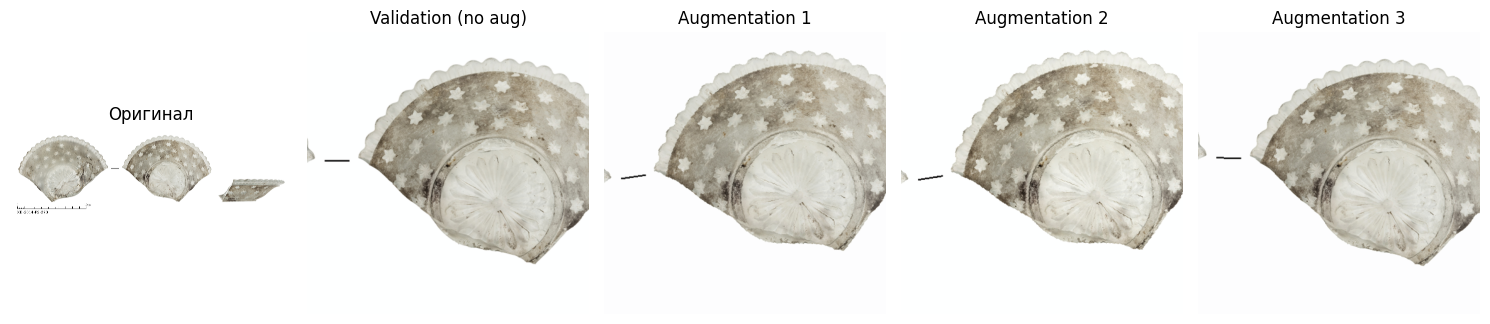

Итоговый размер входа: 448
train_transform: Compose(
    Resize(size=448, interpolation=bicubic, max_size=None, antialias=True)
    Pad(padding=44, fill=255, padding_mode=constant)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=255)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    CenterCrop(size=(448, 448))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
val_transform: Compose(
    Resize(size=448, interpolation=bicubic, max_size=None, antialias=True)
    Pad(padding=44, fill=255, padding_mode=constant)
    CenterCrop(size=(448, 448))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [46]:
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import random

# Константы
IMG_SIZE = 448

# Трансформации для валидации / теста (без аугментаций)
val_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.Pad(int(IMG_SIZE * 0.1), fill=255),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Train-аугментации
train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.Pad(int(IMG_SIZE * 0.1), fill=255),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10, fill=255),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, hue=0, saturation=0),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Загрузка образца
dataset_dir = Path("/content/archaeo_project/data/raw/dataset")
sample_images = list(dataset_dir.glob("*.jpg"))
if sample_images:
    img_path = sample_images[0]
    original_img = Image.open(img_path).convert('RGB')
else:
    original_img = Image.new('RGB', (1000, 800), color='gray')
    print("Изображение не найдено, используется заглушка.")

# Отображение: оригинал, val, 3 аугментации -> всего 5 изображений
plt.figure(figsize=(15, 4))  # шире, чтобы вместить 5 картинок

# 1. Оригинал
plt.subplot(1, 5, 1)
plt.imshow(original_img)
plt.title("Оригинал")
plt.axis('off')

# 2. Валидационная трансформация (без аугментаций)
val_tensor = val_transform(original_img)
val_img = val_tensor.permute(1,2,0).numpy()
val_img = val_img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
val_img = np.clip(val_img, 0, 1)
plt.subplot(1, 5, 2)
plt.imshow(val_img)
plt.title("Validation (no aug)")
plt.axis('off')

# 3-5. Три примера с аугментациями
random.seed(42)
torch.manual_seed(42)
for i in range(3):
    aug_tensor = train_transform(original_img)
    aug_img = aug_tensor.permute(1,2,0).numpy()
    aug_img = aug_img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    aug_img = np.clip(aug_img, 0, 1)
    plt.subplot(1, 5, 3 + i)
    plt.imshow(aug_img)
    plt.title(f"Augmentation {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Итоговый размер входа:", IMG_SIZE)
print("train_transform:", train_transform)
print("val_transform:", val_transform)

### Чего избегаем (вредные аугментации)

- Агрессивный RandomResizedCrop – может вырезать единственное клеймо на close‑up.
- CenterCrop без паддинга – обрезает края multi‑view карточки, где могут быть линейки.
- Изменение hue/saturation – кобальтовая роспись станет зелёной => модель запутается.
- Сильный blur – надписи и цифры становятся нечитаемы.
- Геометрические искажения (перспектива, affine) – разрушают форму фрагмента.
- Mosaic/CutMix – смешивают разные артефакты => метка теряет смысл.

**Задание 10 (3 балла). Реализовать Dataset + DataLoader и сделать финальный sanity-check**

In [48]:
print('hello')

hello


In [51]:
import torch
from torch.utils.data import Dataset, DataLoader

class ArtifactDataset(Dataset):
    def __init__(self, df, transform=None,
                 material_cats=None, name_cats=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

        if material_cats is None:
            self.material_cats = sorted(df['norm_material'].unique())
        else:
            self.material_cats = material_cats
        self.material2idx = {v: i for i, v in enumerate(self.material_cats)}

        if name_cats is None:
            self.name_cats = sorted(df['norm_name'].unique())
        else:
            self.name_cats = name_cats
        self.name2idx = {v: i for i, v in enumerate(self.name_cats)}

        self.idx2material = {i: v for v, i in self.material2idx.items()}
        self.idx2name = {i: v for v, i in self.name2idx.items()}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row['image_path']
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        material_label = self.material2idx[row['norm_material']]
        name_label = self.name2idx[row['norm_name']]
        fragm_label = row['norm_fragm']
        inscription_label = row['norm_inscription']
        targets = {
            'material': torch.tensor(material_label, dtype=torch.long),
            'name': torch.tensor(name_label, dtype=torch.long),
            'fragm': torch.tensor(fragm_label, dtype=torch.float32),
            'inscription': torch.tensor(inscription_label, dtype=torch.float32)
        }
        target_mask = torch.ones(len(targets), dtype=torch.float32)
        metadata = {
            'image_file': row['image_file'],
            'group_key': row['group_key'],
            'code': row['code'],
            'raw_material': row['material'],
            'raw_name': row['name']
        }
        return image, targets, target_mask, metadata


# Загрузка сплитов
PROJECT_ROOT = Path("/content/archaeo_project")
splits_dir = PROJECT_ROOT / "splits"

if not splits_dir.exists():
    raise FileNotFoundError("Сплиты не найдены. ???")

train_df = pd.read_csv(splits_dir / "train.csv")
val_df   = pd.read_csv(splits_dir / "val.csv")
test_df  = pd.read_csv(splits_dir / "test.csv")

dataset_dir = PROJECT_ROOT / "data/raw/dataset"
for df in (train_df, val_df, test_df):
    df['image_path'] = df['image_file'].apply(lambda x: str(dataset_dir / x))

print(f"Train: {len(train_df)} samples, Val: {len(val_df)}, Test: {len(test_df)}")

# Единые словари
full_df = pd.concat([train_df, val_df, test_df])
material_cats = sorted(full_df['norm_material'].unique())
name_cats = sorted(full_df['norm_name'].unique())
print(f"Материалы: {material_cats}")
print(f"Названия: {name_cats}")

# Трансформации (как в задании 9)
IMG_SIZE = 448
val_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.Pad(int(IMG_SIZE * 0.1), fill=255),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.Pad(int(IMG_SIZE * 0.1), fill=255),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10, fill=255),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, hue=0, saturation=0),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = ArtifactDataset(train_df, transform=train_transform,
                                material_cats=material_cats, name_cats=name_cats)
val_dataset   = ArtifactDataset(val_df, transform=val_transform,
                                material_cats=material_cats, name_cats=name_cats)
test_dataset  = ArtifactDataset(test_df, transform=val_transform,
                                material_cats=material_cats, name_cats=name_cats)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Проверка shapes и типов
batch = next(iter(train_loader))
images, targets, target_mask, metadata = batch
print("\n=== SHAPES И TYPES ===")
print(f"Images shape: {images.shape}")
print(f"Images dtype: {images.dtype}")
for k, v in targets.items():
    print(f"  {k}: shape {v.shape}, dtype {v.dtype}")
print(f"Target_mask shape: {target_mask.shape}, dtype: {target_mask.dtype}")

# Декодирование одного элемента
sample_idx = 0
mat_idx = targets['material'][sample_idx].item()
name_idx = targets['name'][sample_idx].item()
fragm_val = targets['fragm'][sample_idx].item()
inscr_val = targets['inscription'][sample_idx].item()

decoded_material = train_dataset.idx2material[mat_idx]
decoded_name = train_dataset.idx2name[name_idx]
decoded_fragm = "Целый" if fragm_val == 1 else "Фрагмент"
decoded_inscr = "есть" if inscr_val == 1 else "нет"

print("\n ДЕКОДИРОВАННЫЕ ПОЛЯ ")
print(f"Изображение: {metadata['image_file'][sample_idx]}")
print(f"Группа: {metadata['group_key'][sample_idx]}")
print(f"norm_material: {decoded_material} (индекс {mat_idx})")
print(f"norm_name: {decoded_name} (индекс {name_idx})")
print(f"fragm: {decoded_fragm}")
print(f"inscription: {decoded_inscr}")


Train: 903 samples, Val: 268, Test: 216
Материалы: ['Дерево', 'Другое', 'Каменная масса', 'Камень', 'Керамика', 'Металл', 'Пластмасса', 'Резина', 'Стекло', 'Фарфор', 'Фаянс']
Названия: ['Блюдце', 'Другое', 'Изразец', 'Крышка', 'Миска', 'Плитка', 'Тарелка']

=== SHAPES И TYPES ===
Images shape: torch.Size([32, 3, 448, 448])
Images dtype: torch.float32
  material: shape torch.Size([32]), dtype torch.int64
  name: shape torch.Size([32]), dtype torch.int64
  fragm: shape torch.Size([32]), dtype torch.float32
  inscription: shape torch.Size([32]), dtype torch.float32
Target_mask shape: torch.Size([32, 4]), dtype: torch.float32

 ДЕКОДИРОВАННЫЕ ПОЛЯ 
Изображение: ВО-1л58-2017-0322_orig.jpg
Группа: ВО-1л58-2017
norm_material: Керамика (индекс 4)
norm_name: Миска (индекс 4)
fragm: Фрагмент
inscription: есть


In [52]:
print("\n SANITY-CHECK")

val_sample = val_dataset[0]
img, _, _, meta = val_sample
print("1. Путь и изображение:")
print(f"   Путь: {meta['image_file']}")
print(f"   Тип img: {type(img)}")

# Отсутствие аугментаций на val (детерминированность)
img1 = val_dataset[0][0]
img2 = val_dataset[0][0]
if torch.equal(img1, img2):
    print("Валидационные трансформации детерминированы.")
else:
    print("Валидационные трансформации недетерминированы!")

#  target_mask
print("3. target_mask первого элемента:", target_mask[0].tolist())
if torch.all(target_mask[0] == 1):
    print("Маска корректна (все 1).")
else:
    print("Маска содержит 0 – возможны пропуски.")

#  Генерация auto_description по ground-truth
def build_auto_description_gt(name, material, fragm, inscription):
    parts = [f"Это {name}", f"из {material}"]
    if fragm == 1:
        parts.append("целый.")
    else:
        parts.append("фрагмент.")
    if inscription == 1:
        parts.append("На поверхности есть роспись или клеймо.")
    else:
        parts.append("На поверхности отсутствуют роспись или клеймо.")
    return " ".join(parts)

auto_desc = build_auto_description_gt(decoded_name, decoded_material, fragm_val, inscr_val)
print(" auto_description по GT:")
print(f"   → {auto_desc}")


 SANITY-CHECK
1. Путь и изображение:
   Путь: Мич11-ш04-155_orig.jpg
   Тип img: <class 'torch.Tensor'>
Валидационные трансформации детерминированы.
3. target_mask первого элемента: [1.0, 1.0, 1.0, 1.0]
Маска корректна (все 1).
 auto_description по GT:
   → Это Миска из Керамика фрагмент. На поверхности есть роспись или клеймо.


Полный путь к файлу: /content/archaeo_project/data/raw/dataset/Мич11-ш04-155_orig.jpg
Файл существует: True


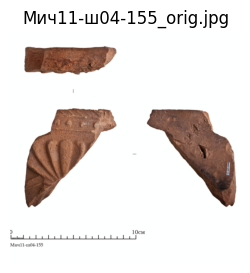

In [53]:
# Берём первый элемент из валидации
idx = 0
img, targets, mask, meta = val_dataset[idx]
full_path = val_dataset.df.iloc[idx]['image_path']

print(f"Полный путь к файлу: {full_path}")
print(f"Файл существует: {Path(full_path).exists()}")

# само изображение (денормализованное)
import matplotlib.pyplot as plt
import numpy as np
img_np = img.permute(1,2,0).numpy()
img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
img_np = np.clip(img_np, 0, 1)
plt.figure(figsize=(3,3))
plt.imshow(img_np)
plt.title(meta['image_file'])
plt.axis('off')
plt.show()
